# PCA, Dimensionality Reduction, and Embeddings

> Visualize high-dimensional data while being careful not to over-interpret a 2D projection.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Fit Principal Component Analysis (PCA) after scaling.
- Interpret explained variance ratios.
- Plot a two-dimensional projection and learn its limitations.
- Understand embeddings as vectors representing complex objects.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine(as_frame=True)
X = StandardScaler().fit_transform(wine.data)
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
plot_df = pd.DataFrame(Z, columns=["PC1", "PC2"])
plot_df["class"] = wine.target.astype(str).values
print("Explained variance ratios:", pca.explained_variance_ratio_.round(3))
print("Cumulative (2 PCs):", round(pca.explained_variance_ratio_.sum(),3))

Explained variance ratios: [0.362 0.192]
Cumulative (2 PCs): 0.554


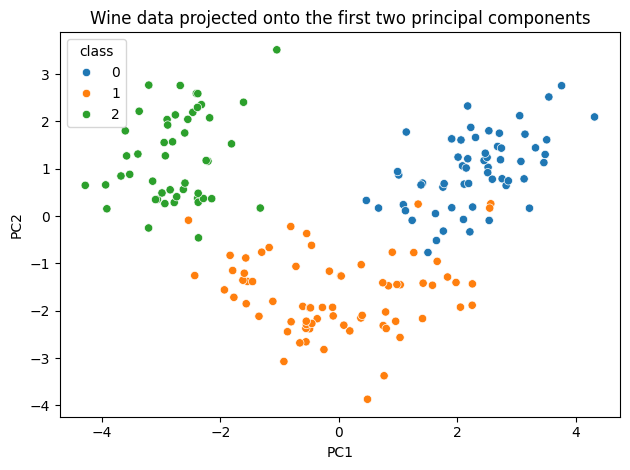

In [2]:
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="class", palette="tab10")
plt.title("Wine data projected onto the first two principal components")
plt.tight_layout()

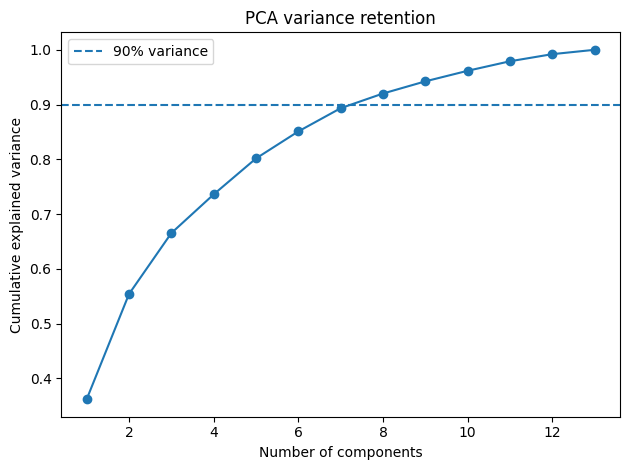

In [3]:
pca_all = PCA().fit(X)
plt.plot(range(1, len(pca_all.explained_variance_ratio_)+1), np.cumsum(pca_all.explained_variance_ratio_), marker="o")
plt.axhline(.9, linestyle="--", label="90% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA variance retention")
plt.legend()
plt.tight_layout()

## PCA versus embeddings
PCA is a linear transformation fitted to a dataset; it preserves directions of high variance, not necessarily class separation or semantic similarity. Learned embeddings (for text, images, or other objects) are produced by a representation model and may encode task-relevant similarity. PCA can later be used to inspect embeddings, but a 2D plot distorts some distances and relationships.

## Practice
1. Compare one, two, and five principal components.
2. Explain why PCA should be fitted on training data when used in a predictive pipeline.
3. Give an example of an embedding and define what “similarity” should mean for that use case.